# TC5061 — Dataset y notebook baseline
**Alumno:** Humberto Alejandro Espinola González
**Matrícula:** A01840066  
**Fecha:** 04/10/2026
**Dataset:** Wine — UCI, distribuido con scikit-learn.

**Pregunta:** ¿es posible clasificar el cultivar de origen de un vino utilizando sus mediciones químicas?
Se trata de clasificación multiclase. Las etiquetas 0, 1 y 2 son categorías, no cantidades.
El objetivo es establecer un punto de partida reproducible, sin optimizar hiperparámetros.

In [2]:
from pathlib import Path
import hashlib
import json
import os
import platform
import random
import sys
from importlib.metadata import version

PROJECT_DIR = Path.cwd().resolve()

# Evita que Matplotlib intente guardar su caché fuera de la carpeta del proyecto.
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_DIR / ".cache" / "matplotlib"))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

from IPython import get_ipython
ipython_session = get_ipython()
if ipython_session is not None:
    ipython_session.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.datasets import load_wine
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

AUTOR = "Humberto Espinola"
SEED = 42
TEST_SIZE = 0.20
EXPERIMENT_NAME = f"TC5061_Baseline_Wine_{AUTOR}"
RESULTS_DIR = PROJECT_DIR / "resultados"
EDA_DIR = RESULTS_DIR / "eda"
EVIDENCE_DIR = PROJECT_DIR / "evidencias"
for folder in [RESULTS_DIR, EDA_DIR, EVIDENCE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

packages = [
    "mlflow", "scikit-learn", "numpy", "pandas", "scipy",
    "matplotlib", "cloudpickle", "jupyterlab", "ipykernel", "nbformat",
]
versions = {package: version(package) for package in packages}
environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": versions,
}
display(pd.Series(versions, name="versión").to_frame())
print("Python:", sys.executable)
print("Carpeta:", PROJECT_DIR)
print("Autor del experimento:", AUTOR)


,versión
mlflow,3.16.1
scikit-learn,1.7.2
numpy,2.3.5
pandas,2.3.3
scipy,1.16.3
matplotlib,3.10.6
cloudpickle,3.1.1
jupyterlab,4.4.7
ipykernel,6.31.0
nbformat,5.10.4


Python: /Users/hespinola/development/mna/mlops/actividad_2/.venv/bin/python
Carpeta: /Users/hespinola/development/mna/mlops/actividad_2
Autor del experimento: Humberto Espinola


## 1. Carga y descripción del dataset
Cada fila representa una muestra de vino. Los 13 predictores contienen mediciones de su composición química y características ópticas; el objetivo identifica uno de tres cultivares.

Wine procede del [repositorio UCI](https://archive.ics.uci.edu/dataset/109/wine).
Se carga con [load_wine de scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.datasets.load_wine.html).
Esta distribución codifica las clases como 0, 1 y 2. No es el dataset Wine Quality ni contiene una calificación de calidad.

In [3]:
dataset = load_wine(as_frame=True)
FEATURES = list(dataset.feature_names)
TARGET = "clase"
df_original = dataset.frame.rename(columns={"target": TARGET}).copy()
CLASS_LABELS = [0, 1, 2]
CLASS_NAMES = ["Clase 0", "Clase 1", "Clase 2"]

# La huella identifica el contenido y el orden de las filas y columnas.
data_bytes = df_original.to_csv(
    index=True, float_format="%.17g", lineterminator="\n"
).encode("utf-8")
DATA_SHA256 = hashlib.sha256(data_bytes).hexdigest()

display(pd.DataFrame({
    "Descripción": ["Registros", "Predictores", "Columnas incluyendo objetivo", "Clases"],
    "Valor": [len(df_original), len(FEATURES), df_original.shape[1],
              df_original[TARGET].nunique()],
}))
display(df_original.head())
df_original.info()
print("Huella SHA-256:", DATA_SHA256)


,Descripción,Valor
0,Registros,178
1,Predictores,13
2,Columnas incluyendo objetivo,14
3,Clases,3


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  clase

In [4]:
meanings = {
    "alcohol": "Medición del contenido de alcohol",
    "malic_acid": "Medición de ácido málico",
    "ash": "Medición de cenizas",
    "alcalinity_of_ash": "Medición de alcalinidad de las cenizas",
    "magnesium": "Medición de magnesio",
    "total_phenols": "Medición de fenoles totales",
    "flavanoids": "Medición de flavonoides",
    "nonflavanoid_phenols": "Medición de fenoles no flavonoides",
    "proanthocyanins": "Medición de proantocianinas",
    "color_intensity": "Intensidad del color",
    "hue": "Tono del color",
    "od280/od315_of_diluted_wines": "Relación de densidad óptica OD280/OD315 en vino diluido",
    "proline": "Medición de prolina",
    "clase": "Cultivar de origen: categoría codificada como 0, 1 o 2",
}
dictionary = pd.DataFrame({
    "tipo_almacenamiento": df_original.dtypes.astype(str),
    "rol": ["Objetivo" if col == TARGET else "Predictor"
            for col in df_original.columns],
    "significado": [meanings[col] for col in df_original.columns],
})
display(dictionary)
dictionary.to_csv(RESULTS_DIR / "diccionario.csv", index_label="variable")


,tipo_almacenamiento,rol,significado
alcohol,float64,Predictor,Medición del contenido de alcohol
malic_acid,float64,Predictor,Medición de ácido málico
ash,float64,Predictor,Medición de cenizas
alcalinity_of_ash,float64,Predictor,Medición de alcalinidad de las cenizas
magnesium,float64,Predictor,Medición de magnesio
total_phenols,float64,Predictor,Medición de fenoles totales
flavanoids,float64,Predictor,Medición de flavonoides
nonflavanoid_phenols,float64,Predictor,Medición de fenoles no flavonoides
proanthocyanins,float64,Predictor,Medición de proantocianinas
color_intensity,float64,Predictor,Intensidad del color


El tipo de almacenamiento no determina el significado estadístico: el objetivo se guarda como entero pero es categórico.
Los predictores se representan como números reales en scikit-learn. No se asignan unidades que no estén confirmadas en la documentación.
Se conservan los 13 predictores; ninguno es un identificador de la clase.

### Auditoría inicial y reserva de la prueba
Se revisan estructura y problemas determinísticos antes de dividir los datos.
La exploración de distribuciones y todas las transformaciones aprendidas se harán después, utilizando entrenamiento.
Esta plantilla está diseñada para Wine: una comprobación fallida indica que debes revisar los datos antes de continuar.

In [5]:
quality = pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "faltantes": df_original.isna().sum(),
    "porcentaje_faltantes": df_original.isna().mean() * 100,
    "valores_distintos": df_original.nunique(),
})
duplicate_rows = int(df_original.duplicated().sum())
duplicate_predictors = int(df_original.duplicated(subset=FEATURES).sum())

# Predictores idénticos con etiquetas distintas requieren investigar su origen.
conflicting_groups = int(
    (df_original.groupby(FEATURES, dropna=False)[TARGET].nunique() > 1).sum()
)
display(quality)
print("Filas completas duplicadas:", duplicate_rows)
print("Predictores idénticos:", duplicate_predictors)
print("Grupos con etiquetas contradictorias:", conflicting_groups)

# Conversiones por un esquema conocido; no se aprende ninguna estadística aquí.
numeric_features = df_original[FEATURES].apply(pd.to_numeric, errors="coerce")
new_missing_from_types = int(
    (numeric_features.isna() & df_original[FEATURES].notna()).sum().sum()
)
infinite_values = int(np.isinf(numeric_features.to_numpy()).sum())
numeric_features = numeric_features.replace([np.inf, -np.inf], np.nan)

if df_original[TARGET].isna().any():
    raise ValueError("Hay etiquetas faltantes: no se pueden imputar como predictores.")
if not set(df_original[TARGET].unique()).issubset(CLASS_LABELS):
    raise ValueError("Se encontraron etiquetas fuera del esquema esperado de Wine.")
if duplicate_rows or duplicate_predictors or conflicting_groups:
    raise ValueError("Revisa duplicados y grupos antes de dividir este dataset.")
if new_missing_from_types:
    raise ValueError("Hay valores que no se pueden convertir al tipo numérico esperado.")

df_clean = numeric_features.astype("float64").copy()
df_clean[TARGET] = df_original[TARGET].astype("int64")
quality.to_csv(RESULTS_DIR / "auditoria.csv", index_label="variable")
print("Valores infinitos convertidos a faltantes:", infinite_values)
print("Conversiones fallidas de tipos:", new_missing_from_types)
print("Filas conservadas:", len(df_clean))


,tipo,faltantes,porcentaje_faltantes,valores_distintos
alcohol,float64,0,0.0,126
malic_acid,float64,0,0.0,133
ash,float64,0,0.0,79
alcalinity_of_ash,float64,0,0.0,63
magnesium,float64,0,0.0,53
total_phenols,float64,0,0.0,97
flavanoids,float64,0,0.0,132
nonflavanoid_phenols,float64,0,0.0,39
proanthocyanins,float64,0,0.0,101
color_intensity,float64,0,0.0,132


Filas completas duplicadas: 0
Predictores idénticos: 0
Grupos con etiquetas contradictorias: 0
Valores infinitos convertidos a faltantes: 0
Conversiones fallidas de tipos: 0
Filas conservadas: 178


In [6]:
X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

# Estratificar mantiene aproximadamente las proporciones de las tres clases.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED,
)
display(pd.DataFrame({
    "conjunto": ["Entrenamiento", "Prueba"],
    "filas": [len(X_train), len(X_test)],
    "porcentaje": [100 * len(X_train) / len(X), 100 * len(X_test) / len(X)],
}))
print("La prueba queda reservada hasta la evaluación del baseline.")
split_indices = pd.DataFrame({
    "fila_original": list(X_train.index) + list(X_test.index),
    "conjunto": ["train"] * len(X_train) + ["test"] * len(X_test),
})
split_indices.to_csv(RESULTS_DIR / "particion.csv", index=False)


,conjunto,filas,porcentaje
0,Entrenamiento,142,79.775281
1,Prueba,36,20.224719


La prueba queda reservada hasta la evaluación del baseline.


## 2. Análisis exploratorio — solamente entrenamiento
Se examinan el balance de clases, las escalas y distribuciones de los predictores y sus relaciones.
Los gráficos se guardan como evidencia y luego se registran en MLflow.

,filas,porcentaje
clase,,
0,47,33.098592
1,57,40.140845
2,38,26.760563


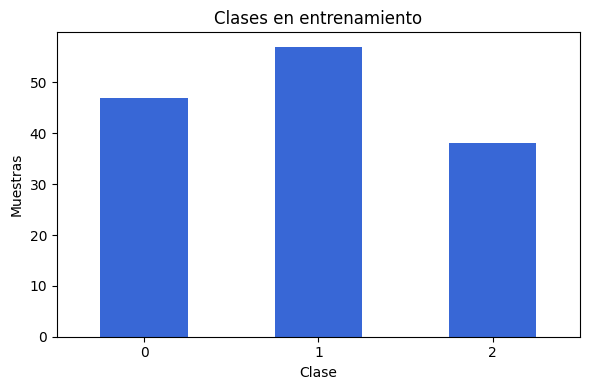

In [7]:
counts = y_train.value_counts().sort_index()
class_summary = counts.rename("filas").to_frame()
class_summary["porcentaje"] = 100 * counts / len(y_train)
display(class_summary)
fig, ax = plt.subplots(figsize=(6, 4))
counts.plot.bar(ax=ax, color="#3867d6", rot=0)
ax.set(title="Clases en entrenamiento", xlabel="Clase", ylabel="Muestras")
fig.tight_layout()
fig.savefig(EDA_DIR / "balance_clases.png", dpi=140, bbox_inches="tight")
plt.show()


,count,mean,std,min,25%,50%,75%,max
alcohol,142.0,12.971479,0.802521,11.03,12.3700,13.010,13.5600,14.83
malic_acid,142.0,2.340000,1.101285,0.74,1.6100,1.810,3.1700,5.80
ash,142.0,2.364859,0.268380,1.36,2.2000,2.360,2.5600,3.22
alcalinity_of_ash,142.0,19.625352,3.380848,10.60,17.2000,19.500,21.5000,30.00
magnesium,142.0,99.633803,14.937448,70.00,88.0000,97.000,107.7500,162.00
total_phenols,142.0,2.273732,0.621454,0.98,1.7050,2.335,2.8000,3.88
flavanoids,142.0,1.985352,0.951952,0.34,1.2275,2.135,2.7750,3.74
nonflavanoid_phenols,142.0,0.360141,0.119211,0.13,0.2700,0.340,0.4300,0.63
proanthocyanins,142.0,1.600211,0.579777,0.42,1.2500,1.560,1.9500,3.58
color_intensity,142.0,4.989648,2.334947,1.28,3.0575,4.640,6.1825,13.00


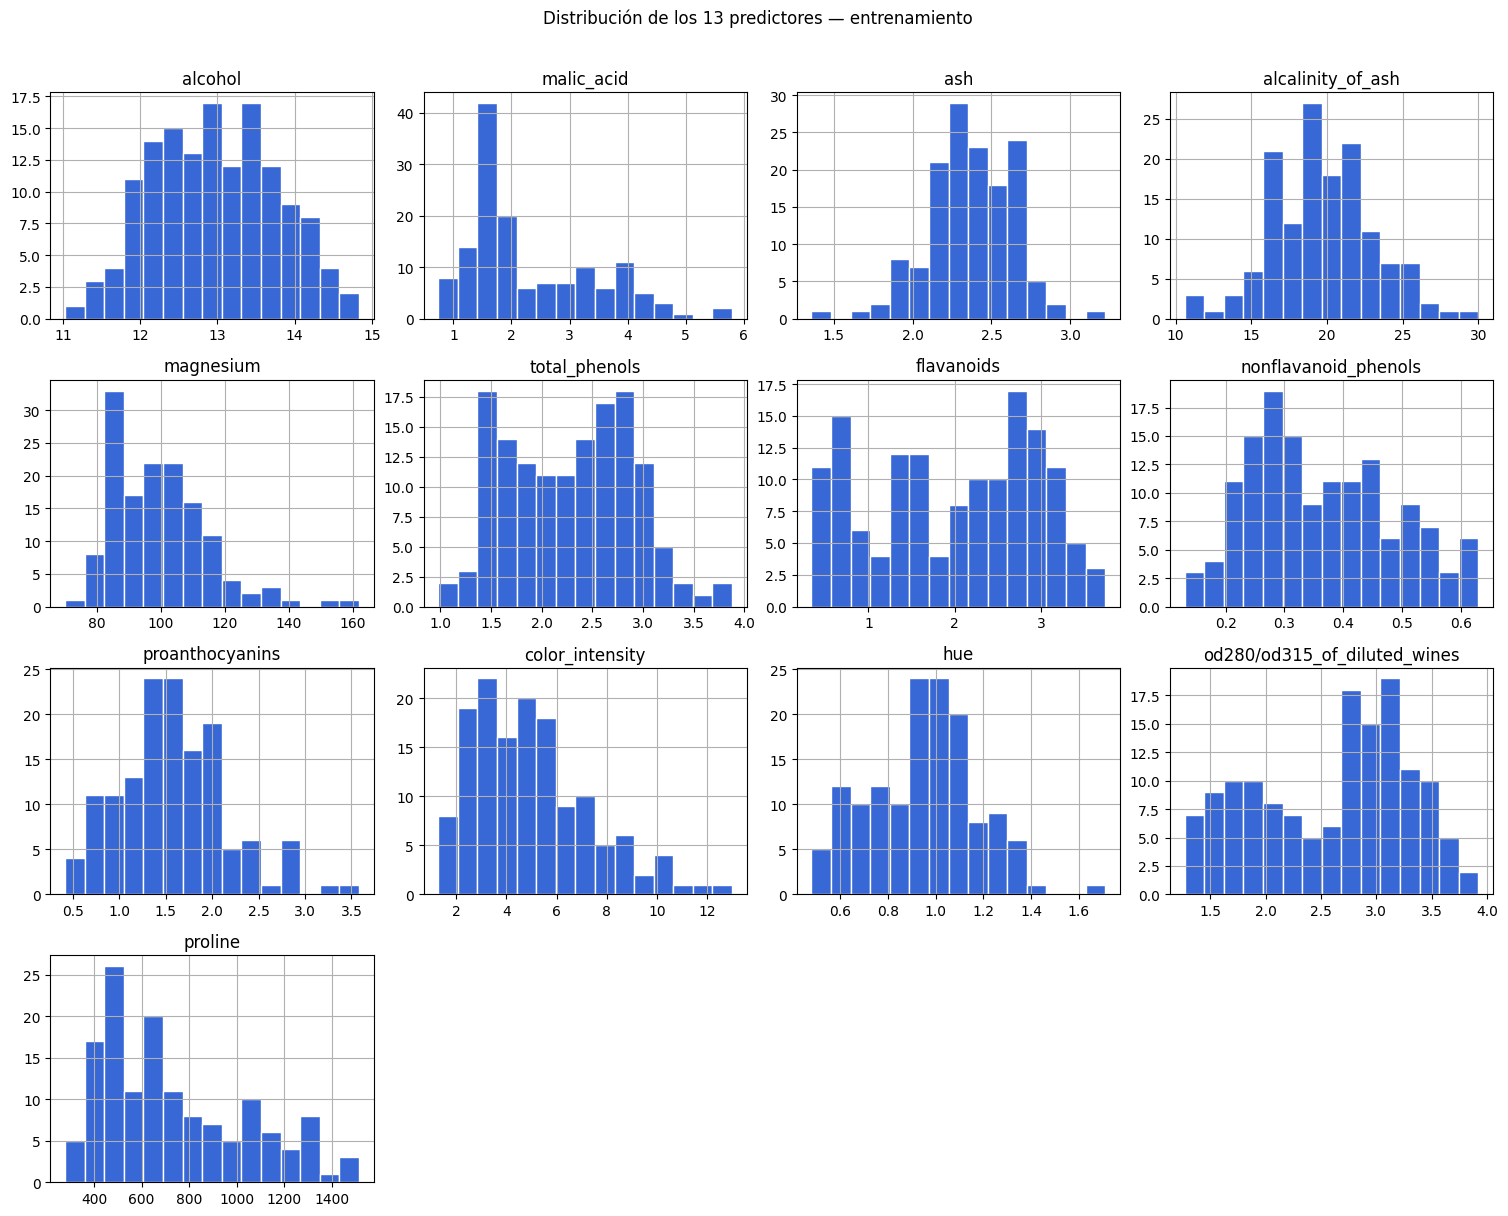

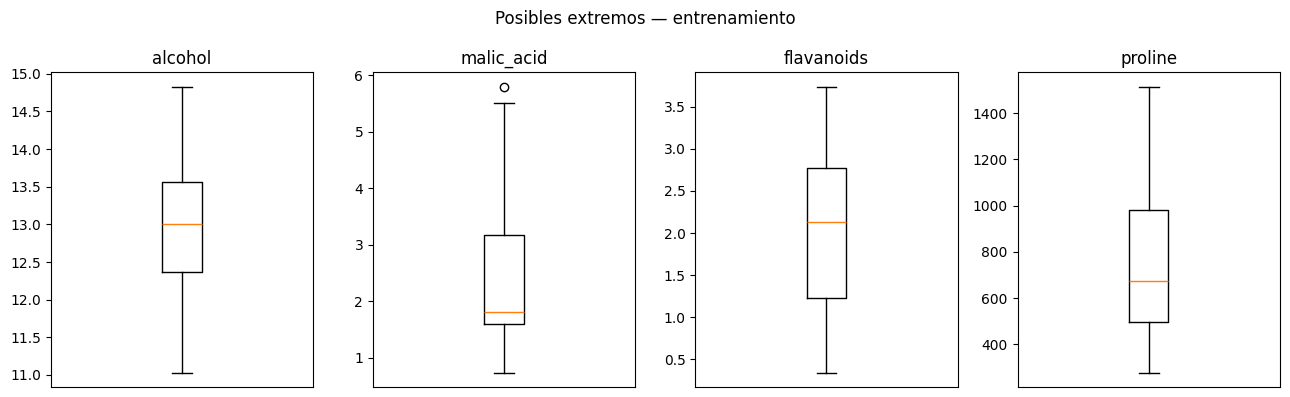

In [8]:
descriptive_stats = X_train.describe().T
display(descriptive_stats)
descriptive_stats.to_csv(RESULTS_DIR / "estadisticas_entrenamiento.csv")

X_train.hist(bins=15, figsize=(15, 12), color="#3867d6", edgecolor="white")
fig = plt.gcf()
fig.suptitle("Distribución de los 13 predictores — entrenamiento", y=1.01)
fig.tight_layout()
fig.savefig(EDA_DIR / "histogramas.png", dpi=140, bbox_inches="tight")
plt.show()

# Se separan los gráficos para que las diferentes escalas sean legibles.
box_features = ["alcohol", "malic_acid", "flavanoids", "proline"]
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for ax, feature in zip(axes, box_features):
    ax.boxplot(X_train[feature].dropna())
    ax.set(title=feature, xticks=[])
fig.suptitle("Posibles extremos — entrenamiento")
fig.tight_layout()
fig.savefig(EDA_DIR / "boxplots.png", dpi=140, bbox_inches="tight")
plt.show()


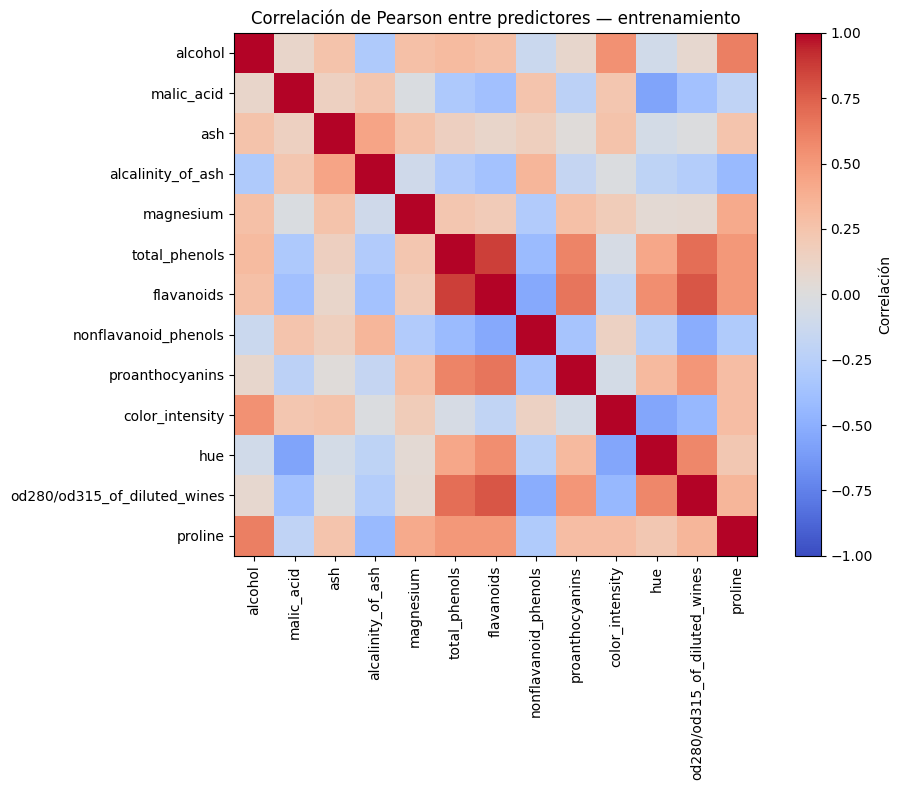

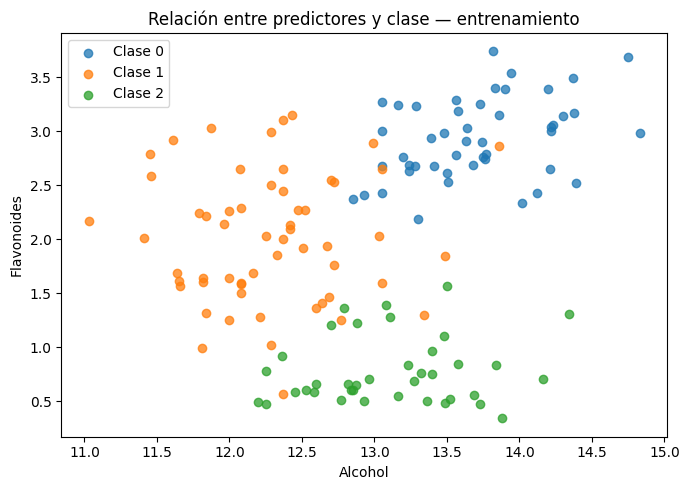

,alcohol,flavanoids,proline
clase,,,
0,13.680,2.940,1080.0
1,12.290,2.010,495.0
2,13.095,0.675,622.5


In [9]:
correlations = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_title("Correlación de Pearson entre predictores — entrenamiento")
fig.colorbar(im, ax=ax, label="Correlación")
fig.tight_layout()
fig.savefig(EDA_DIR / "correlaciones.png", dpi=140, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for label, name in zip(CLASS_LABELS, CLASS_NAMES):
    rows = y_train == label
    ax.scatter(
        X_train.loc[rows, "alcohol"], X_train.loc[rows, "flavanoids"],
        label=name, alpha=0.75,
    )
ax.set(
    xlabel="Alcohol", ylabel="Flavonoides",
    title="Relación entre predictores y clase — entrenamiento",
)
ax.legend()
fig.tight_layout()
fig.savefig(EDA_DIR / "dispersion_por_clase.png", dpi=140, bbox_inches="tight")
plt.show()

training_frame = X_train.assign(clase=y_train)
display(training_frame.groupby(TARGET)[["alcohol", "flavanoids", "proline"]].median())


In [10]:
# Resumen calculado; no utiliza la prueba para seleccionar variables.
upper = correlations.where(np.triu(np.ones(correlations.shape), k=1).astype(bool))
pairs = upper.stack()
strongest_pair = pairs.abs().idxmax()
strongest_corr = float(pairs.loc[strongest_pair])
skew = X_train.skew().abs().sort_values(ascending=False)
scales = X_train.std()
summary_eda = (
    f"En entrenamiento hay {len(X_train)} muestras. Las clases tienen entre "
    f"{int(counts.min())} y {int(counts.max())} observaciones. "
    f"La mayor correlación absoluta entre predictores corresponde a "
    f"{strongest_pair[0]} y {strongest_pair[1]} (r={strongest_corr:.3f}); "
    "describe asociación lineal, sin demostrar causalidad. "
    f"Las mayores asimetrías absolutas aparecen en {', '.join(skew.index[:3])}. "
    f"Las desviaciones estándar van de {scales.min():.3f} a {scales.max():.3f} "
    "en sus escalas originales, lo que justifica estandarizar para este modelo. "
    "Se conservarán todos los predictores para establecer el baseline."
)
display(Markdown(summary_eda))


En entrenamiento hay 142 muestras. Las clases tienen entre 38 y 57 observaciones. La mayor correlación absoluta entre predictores corresponde a total_phenols y flavanoids (r=0.861); describe asociación lineal, sin demostrar causalidad. Las mayores asimetrías absolutas aparecen en magnesium, malic_acid, color_intensity. Las desviaciones estándar van de 0.119 a 301.499 en sus escalas originales, lo que justifica estandarizar para este modelo. Se conservarán todos los predictores para establecer el baseline.

### Observaciones del análisis exploratorio

El conjunto de entrenamiento contiene 142 muestras: 47 de la clase 0, 57 de la clase 1 y 38 de la clase 2, equivalentes aproximadamente al 33.10%, 40.14% y 26.76%. Existe una diferencia moderada entre sus frecuencias. Por ello, además de accuracy, utilizaré F1 macro para evaluar el desempeño dando el mismo peso a cada clase y evitar que la clase más frecuente domine el resultado agregado.

Los predictores presentan escalas diferentes. Por ejemplo, la desviación estándar de `proline` es aproximadamente 301.50, mientras que la de `nonflavanoid_phenols` es 0.12. Esto justifica la estandarización antes de entrenar la regresión logística, ya que la escala de los predictores influye en su regularización. Los histogramas también muestran asimetría en variables como `magnesium`, `malic_acid` y `color_intensity`.

La mayor correlación absoluta entre predictores se observa entre `total_phenols` y `flavanoids`, con un valor aproximado de 0.861. Esta asociación indica que ambas variables contienen información relacionada, aunque no demuestra causalidad. Para establecer el baseline conservaré los 13 predictores.

En la gráfica de alcohol y flavonoides se aprecia que la clase 2 tiende a presentar valores menores de flavonoides, mientras que la clase 0 suele tener valores mayores. Sin embargo, existe superposición entre algunas muestras. Estas diferencias sugieren información útil para la clasificación, pero dos variables por sí solas no garantizan una separación perfecta.

## 3. Limpieza y decisiones documentadas
Se usa la regla de 1.5 veces el rango intercuartílico (IQR) para identificar **posibles** outliers.
Los límites se calculan con entrenamiento. Esta regla no demuestra que una medición sea incorrecta:
una distribución que reúne distintos cultivares puede contener extremos válidos.

Se conservan esos valores porque no hay evidencia de error ni rangos de dominio que justifiquen eliminarlos.
La estandarización no los elimina ni recorta. La imputación por mediana se ajustará dentro del pipeline;
si no existen faltantes, no sustituirá observaciones.

In [11]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_flags = X_train.lt(lower) | X_train.gt(upper_bound)

outlier_report = pd.DataFrame({
    "limite_inferior": lower,
    "limite_superior": upper_bound,
    "posibles_outliers_train": outlier_flags.sum(),
    "porcentaje_train": 100 * outlier_flags.mean(),
})
display(outlier_report)
outlier_rows = int(outlier_flags.any(axis=1).sum())
print("Filas de entrenamiento con al menos un posible outlier:", outlier_rows)
outlier_report.to_csv(RESULTS_DIR / "outliers_entrenamiento.csv", index_label="variable")

decisions = [
    {
        "problema": "Faltantes",
        "evidencia": f"{int(df_clean[FEATURES].isna().sum().sum())} valores faltantes en predictores",
        "decision": "Imputador por mediana ajustado solo con entrenamiento; sin faltantes no modifica valores.",
        "justificacion": "Conservar filas y evitar aprender estadísticas de prueba.",
    },
    {
        "problema": "Duplicados",
        "evidencia": f"{duplicate_rows} filas repetidas y {conflicting_groups} grupos contradictorios",
        "decision": "Conservar las filas; no se detectó un problema que requiera eliminarlas.",
        "justificacion": "No alterar los datos sin evidencia; impedir grupos repetidos en train y test.",
    },
    {
        "problema": "Tipos e infinitos",
        "evidencia": f"{new_missing_from_types} conversiones fallidas; {infinite_values} infinitos",
        "decision": "Predictores float64; objetivo entero con significado categórico. Infinitos se marcan como faltantes.",
        "justificacion": "Esquema numérico compatible con el modelo y etiquetas válidas.",
    },
    {
        "problema": "Posibles outliers",
        "evidencia": f"{outlier_rows} de {len(X_train)} filas train señaladas por IQR",
        "decision": "Conservar todos los extremos; no se aplican recortes.",
        "justificacion": "IQR es un diagnóstico estadístico; puede señalar diferencias reales entre cultivares.",
    },
    {
        "problema": "Escalas diferentes",
        "evidencia": "Desviaciones estándar en escalas originales distintas",
        "decision": "StandardScaler dentro del pipeline, ajustado solo con entrenamiento.",
        "justificacion": "La escala afecta la regularización de la regresión logística.",
    },
]
display(pd.DataFrame(decisions))
(RESULTS_DIR / "decisiones_limpieza.json").write_text(
    json.dumps(decisions, ensure_ascii=False, indent=2), encoding="utf-8"
)


,limite_inferior,limite_superior,posibles_outliers_train,porcentaje_train
alcohol,10.58500,15.34500,0,0.000000
malic_acid,-0.73000,5.51000,1,0.704225
ash,1.66000,3.10000,2,1.408451
alcalinity_of_ash,10.75000,27.95000,3,2.112676
magnesium,58.37500,137.37500,3,2.112676
total_phenols,0.06250,4.44250,0,0.000000
flavanoids,-1.09375,5.09625,0,0.000000
nonflavanoid_phenols,0.03000,0.67000,0,0.000000
proanthocyanins,0.20000,3.00000,2,1.408451
color_intensity,-1.63000,10.87000,2,1.408451


Filas de entrenamiento con al menos un posible outlier: 11


,problema,evidencia,decision,justificacion
0,Faltantes,0 valores faltantes en predictores,Imputador por mediana ajustado solo con entren...,Conservar filas y evitar aprender estadísticas...
1,Duplicados,0 filas repetidas y 0 grupos contradictorios,Conservar las filas; no se detectó un problema...,No alterar los datos sin evidencia; impedir gr...
2,Tipos e infinitos,0 conversiones fallidas; 0 infinitos,Predictores float64; objetivo entero con signi...,Esquema numérico compatible con el modelo y et...
3,Posibles outliers,11 de 142 filas train señaladas por IQR,Conservar todos los extremos; no se aplican re...,IQR es un diagnóstico estadístico; puede señal...
4,Escalas diferentes,Desviaciones estándar en escalas originales di...,"StandardScaler dentro del pipeline, ajustado s...",La escala afecta la regularización de la regre...


1473

## 4. Entrenamiento del modelo base
Se usa regresión logística para clasificación multiclase, con regularización L2 y C=1.
Es un baseline sencillo; no se realiza búsqueda de hiperparámetros ni selección de variables.

El pipeline contiene imputación por mediana, estandarización y clasificador. Su ajuste aprende todas las
estadísticas exclusivamente de entrenamiento. Se añade una referencia mayoritaria que ignora los predictores.
Los dos modelos y la métrica principal se fijan antes de evaluar la prueba.

In [12]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=1000, random_state=SEED,
    )),
])
reference = DummyClassifier(strategy="most_frequent")

# fit se invoca solamente con entrenamiento.
model.fit(X_train, y_train)
reference.fit(X_train, y_train)
print("Baseline y referencia entrenados.")
print("Iteraciones del clasificador:", model.named_steps["classifier"].n_iter_)


Baseline y referencia entrenados.
Iteraciones del clasificador: [17]


## 5. Evaluación del baseline
La métrica principal es **F1 macro**: calcula F1 para cada clase y después promedia con igual peso.
Se informa también accuracy, precision y recall macro, reporte por clase y matriz de confusión.
Accuracy expresa proporción de aciertos; F1 no tiene esa interpretación.

La prueba se utiliza para evaluar esta configuración predefinida. No se reutiliza para ajustar el modelo.

,valor
test_accuracy,0.972222
test_f1_macro,0.970962
test_precision_macro,0.977778
test_recall_macro,0.966667
train_accuracy,1.000000
train_f1_macro,1.000000
reference_test_accuracy,0.388889
reference_test_f1_macro,0.186667


,precision,recall,f1-score,support
Clase 0,1.000000,1.000000,1.000000,12.000000
Clase 1,0.933333,1.000000,0.965517,14.000000
Clase 2,1.000000,0.900000,0.947368,10.000000
accuracy,0.972222,0.972222,0.972222,0.972222
macro avg,0.977778,0.966667,0.970962,36.000000
weighted avg,0.974074,0.972222,0.971970,36.000000


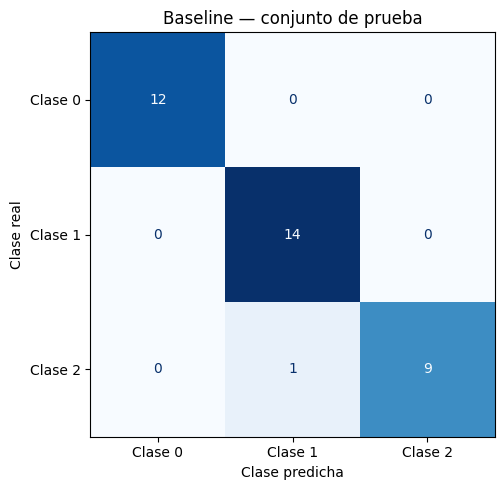

In [13]:
y_pred = model.predict(X_test)
train_pred = model.predict(X_train)
reference_pred = reference.predict(X_test)

metrics = {
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_f1_macro": float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
    "test_precision_macro": float(precision_score(
        y_test, y_pred, average="macro", zero_division=0)),
    "test_recall_macro": float(recall_score(
        y_test, y_pred, average="macro", zero_division=0)),
    "train_accuracy": float(accuracy_score(y_train, train_pred)),
    "train_f1_macro": float(f1_score(
        y_train, train_pred, average="macro", zero_division=0)),
    "reference_test_accuracy": float(accuracy_score(y_test, reference_pred)),
    "reference_test_f1_macro": float(f1_score(
        y_test, reference_pred, average="macro", zero_division=0)),
}
display(pd.Series(metrics, name="valor").to_frame())

report = classification_report(
    y_test, y_pred, labels=CLASS_LABELS, target_names=CLASS_NAMES,
    output_dict=True, zero_division=0,
)
display(pd.DataFrame(report).T)
cm = confusion_matrix(y_test, y_pred, labels=CLASS_LABELS)
fig_cm, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax, cmap="Blues", colorbar=False,
)
ax.set(title="Baseline — conjunto de prueba", xlabel="Clase predicha", ylabel="Clase real")
fig_cm.tight_layout()
fig_cm.savefig(RESULTS_DIR / "matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()


In [14]:
correct = int((y_test.to_numpy() == y_pred).sum())
errors = len(y_test) - correct
delta_f1 = metrics["test_f1_macro"] - metrics["reference_test_f1_macro"]
recalls = {name: float(report[name]["recall"]) for name in CLASS_NAMES}
lowest_recall = min(recalls.values())
lowest_classes = [name for name, value in recalls.items()
                  if np.isclose(value, lowest_recall)]

error_descriptions = [
    f"{int(cm[i, j])} de {CLASS_NAMES[i]} se predijeron como {CLASS_NAMES[j]}"
    for i in range(len(CLASS_LABELS))
    for j in range(len(CLASS_LABELS))
    if i != j and cm[i, j] > 0
]
error_text = "; ".join(error_descriptions) if error_descriptions else "No hubo errores en esta partición"
reference_relation = (
    "supera" if delta_f1 > 0 else "iguala" if delta_f1 == 0 else "queda por debajo de"
)
interpretation = (
    f"El baseline clasificó correctamente {correct} de {len(y_test)} muestras de prueba "
    f"y cometió {errors} errores: accuracy={metrics['test_accuracy']:.4f}. "
    f"El F1 macro fue {metrics['test_f1_macro']:.4f}; promedia el balance de precision "
    "y recall de cada clase con igual peso y no es un porcentaje de aciertos. "
    f"En F1 macro, el modelo {reference_relation} la referencia mayoritaria "
    f"({metrics['reference_test_f1_macro']:.4f}), con diferencia {delta_f1:+.4f}. "
    f"El menor recall correspondió a {', '.join(lowest_classes)} "
    f"({lowest_recall:.4f}). {error_text}. "
    f"El F1 macro de entrenamiento fue {metrics['train_f1_macro']:.4f}; "
    "la diferencia con prueba es descriptiva y por sí sola no demuestra sobreajuste. "
    f"La prueba contiene solamente {len(y_test)} casos: un error equivale a "
    f"{100 / len(y_test):.2f} puntos porcentuales de accuracy. "
    "Una partición pequeña y un dataset histórico sencillo limitan la generalización "
    "de estos resultados. Harían falta validación dentro del entrenamiento y datos "
    "independientes representativos antes de valorar su uso operativo."
)
display(Markdown(interpretation))

predictions = pd.DataFrame({
    "fila_original": X_test.index,
    "clase_real": y_test.to_numpy(),
    "clase_predicha": y_pred,
    "prediccion_referencia": reference_pred,
})
predictions.to_csv(RESULTS_DIR / "predicciones_prueba.csv", index=False)
(RESULTS_DIR / "metricas.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)
(RESULTS_DIR / "interpretacion.txt").write_text(interpretation, encoding="utf-8")


El baseline clasificó correctamente 35 de 36 muestras de prueba y cometió 1 errores: accuracy=0.9722. El F1 macro fue 0.9710; promedia el balance de precision y recall de cada clase con igual peso y no es un porcentaje de aciertos. En F1 macro, el modelo supera la referencia mayoritaria (0.1867), con diferencia +0.7843. El menor recall correspondió a Clase 2 (0.9000). 1 de Clase 2 se predijeron como Clase 1. El F1 macro de entrenamiento fue 1.0000; la diferencia con prueba es descriptiva y por sí sola no demuestra sobreajuste. La prueba contiene solamente 36 casos: un error equivale a 2.78 puntos porcentuales de accuracy. Una partición pequeña y un dataset histórico sencillo limitan la generalización de estos resultados. Harían falta validación dentro del entrenamiento y datos independientes representativos antes de valorar su uso operativo.

853

### Interpretación de los resultados

La regresión logística clasificó correctamente 35 de las 36 muestras de prueba, obteniendo una accuracy de 0.9722, equivalente al 97.22% de aciertos. El F1 macro fue 0.9710. Esta métrica resume el equilibrio entre precision y recall de cada clase y después promedia los resultados con igual peso, por lo que resulta pertinente para evaluar las tres categorías. No debe interpretarse como un porcentaje de aciertos.

El modelo superó a la referencia que siempre predice la clase mayoritaria. Esta referencia obtuvo una accuracy de 0.3889 y un F1 macro de 0.1867. La diferencia indica que, en esta partición, utilizar las características químicas aporta capacidad predictiva frente a una estrategia que ignora los predictores.

La matriz de confusión muestra que las 12 muestras de la clase 0 y las 14 de la clase 1 fueron clasificadas correctamente. En la clase 2 se identificaron correctamente nueve de diez muestras; la restante fue predicha como clase 1. Por tanto, la clase 2 presentó el menor recall, con un valor de 0.90.

En entrenamiento, accuracy y F1 macro fueron iguales a 1.0. Aunque estos resultados son superiores a los de prueba, esta diferencia por sí sola no demuestra sobreajuste. La prueba contiene únicamente 36 observaciones y un error representa aproximadamente 2.78 puntos porcentuales de accuracy. Por ello, considero el resultado un punto de partida favorable, pero insuficiente para afirmar que el desempeño será estable en producción. Para evaluar futuras mejoras utilizaría validación dentro del entrenamiento y una prueba independiente representativa del contexto de uso.

## 6. Registro del experimento en MLflow Tracking
Se registran parámetros, métricas, metadatos del dataset y artefactos.
El pipeline completo se conserva para reproducir inferencia, con firma y ejemplo de entrada.
No se requiere Model Registry para cumplir esta actividad.

Se usa una base SQLite local y una ubicación explícita para artefactos. Al repetir el notebook,
cada ejecución crea una corrida nueva en el mismo experimento. Conserva las versiones para repetir los resultados.
Documentación: [MLflow Tracking](https://mlflow.org/docs/latest/ml/tracking/) y
[modelos scikit-learn en MLflow](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html).

In [15]:
# Ruta absoluta para que Tracking no dependa de la carpeta de una segunda terminal.
TRACKING_URI = f"sqlite:///{PROJECT_DIR / 'mlflow_baseline.db'}"
mlflow.set_tracking_uri(TRACKING_URI)
client = MlflowClient()

# Crear el experimento con almacenamiento de artefactos explícito.
experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    artifact_folder = PROJECT_DIR / "mlartifacts" / EXPERIMENT_NAME
    artifact_folder.mkdir(parents=True, exist_ok=True)
    experiment_id = mlflow.create_experiment(
        EXPERIMENT_NAME, artifact_location=artifact_folder.as_uri(),
    )
else:
    experiment_id = experiment.experiment_id
mlflow.set_experiment(EXPERIMENT_NAME)

classifier = model.named_steps["classifier"]
params = {
    "dataset": "Wine_UCI_sklearn",
    "model": "LogisticRegression",
    "C": classifier.C,
    "penalty": classifier.penalty,
    "solver": classifier.solver,
    "max_iter": classifier.max_iter,
    "seed": SEED,
    "test_size": TEST_SIZE,
    "split_strategy": "stratified_random",
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "n_features": len(FEATURES),
    "imputer": "median",
    "scaler": "StandardScaler",
    "outlier_policy": "retain_IQR_flags_without_evidence_of_error",
    "reference_strategy": "most_frequent",
    "primary_metric": "test_f1_macro",
    "dataset_sha256": DATA_SHA256,
}
model_requirements = [
    f"{package}=={versions[package]}"
    for package in ["scikit-learn", "numpy", "pandas", "scipy", "cloudpickle"]
]
input_example = X_train.head(3).copy()
signature = infer_signature(input_example, model.predict(input_example))

with mlflow.start_run(run_name="baseline_regresion_logistica") as run:
    mlflow.set_tags({
        "autor": AUTOR,
        "actividad": "TC5061_Dataset_Notebook",
        "purpose": "baseline",
        "dataset_source": "https://archive.ics.uci.edu/dataset/109/wine",
    })
    mlflow.log_params(params)
    mlflow.log_metrics(metrics)
    mlflow.log_dict(environment, "reproducibilidad/entorno.json")
    mlflow.log_dict(report, "evaluacion/reporte_por_clase.json")
    mlflow.log_dict(decisions, "limpieza/decisiones.json")
    mlflow.log_text(interpretation, "evaluacion/interpretacion.txt")
    mlflow.log_artifacts(str(EDA_DIR), artifact_path="eda")
    for filename, folder in [
        ("diccionario.csv", "datos"),
        ("auditoria.csv", "limpieza"),
        ("outliers_entrenamiento.csv", "limpieza"),
        ("particion.csv", "reproducibilidad"),
        ("predicciones_prueba.csv", "evaluacion"),
        ("matriz_confusion.png", "evaluacion"),
        ("metricas.json", "evaluacion"),
    ]:
        mlflow.log_artifact(str(RESULTS_DIR / filename), artifact_path=folder)
    mlflow.log_artifact(
        str(PROJECT_DIR / "requirements.txt"), artifact_path="reproducibilidad",
    )
    # Registrar metadatos de los datos usados; no se crea un servicio remoto.
    train_dataset = mlflow.data.from_pandas(
        X_train.assign(clase=y_train),
        source="https://archive.ics.uci.edu/dataset/109/wine",
        targets=TARGET, name="Wine_train",
    )
    mlflow.log_input(train_dataset, context="training")
    model_info = mlflow.sklearn.log_model(
        sk_model=model,
        name="modelo_baseline",
        signature=signature,
        input_example=input_example,
        pip_requirements=model_requirements,
        serialization_format="cloudpickle",
    )
    RUN_ID = run.info.run_id

saved_run = client.get_run(RUN_ID)
run_summary = {
    "experiment_name": EXPERIMENT_NAME,
    "experiment_id": experiment_id,
    "run_id": RUN_ID,
    "status": saved_run.info.status,
    "model_uri": model_info.model_uri,
    "tracking_uri": TRACKING_URI,
    "metrics": saved_run.data.metrics,
}
(RESULTS_DIR / "resumen_mlflow.json").write_text(
    json.dumps(run_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Experimento:", EXPERIMENT_NAME)
print("Run ID:", RUN_ID)
print("Estado:", saved_run.info.status)
print("URI del modelo:", model_info.model_uri)
display(pd.Series(saved_run.data.metrics, name="métrica registrada").to_frame())


2026/10/04 23:27:45 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/04 23:27:45 INFO mlflow.store.db.utils: Updating database tables
/Users/hespinola/development/mna/mlops/actividad_2/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/04 23:27:45 WARNING mlflow.skl

Experimento: TC5061_Baseline_Wine_Humberto Espinola
Run ID: ff409bcea194449893a88ee7f27c1df8
Estado: FINISHED
URI del modelo: models:/m-6e31bf6973274aac831d1d6a45b89c1e


,métrica registrada
test_accuracy,0.972222
test_f1_macro,0.970962
test_precision_macro,0.977778
test_recall_macro,0.966667
train_accuracy,1.000000
train_f1_macro,1.000000
reference_test_accuracy,0.388889
reference_test_f1_macro,0.186667


In [16]:
# Comprobar que el pipeline guardado conserva el preprocesamiento y sus predicciones.
loaded_model = mlflow.sklearn.load_model(model_info.model_uri)
loaded_predictions = loaded_model.predict(X_test)
same_predictions = bool(np.array_equal(y_pred, loaded_predictions))
print("El modelo recargado reproduce las predicciones:", same_predictions)
if not same_predictions:
    raise RuntimeError("El modelo guardado no reproduce las predicciones originales.")
if saved_run.info.status != "FINISHED":
    raise RuntimeError("La corrida no finalizó correctamente.")


El modelo recargado reproduce las predicciones: True


### Evidencia del experimento registrado en MLflow

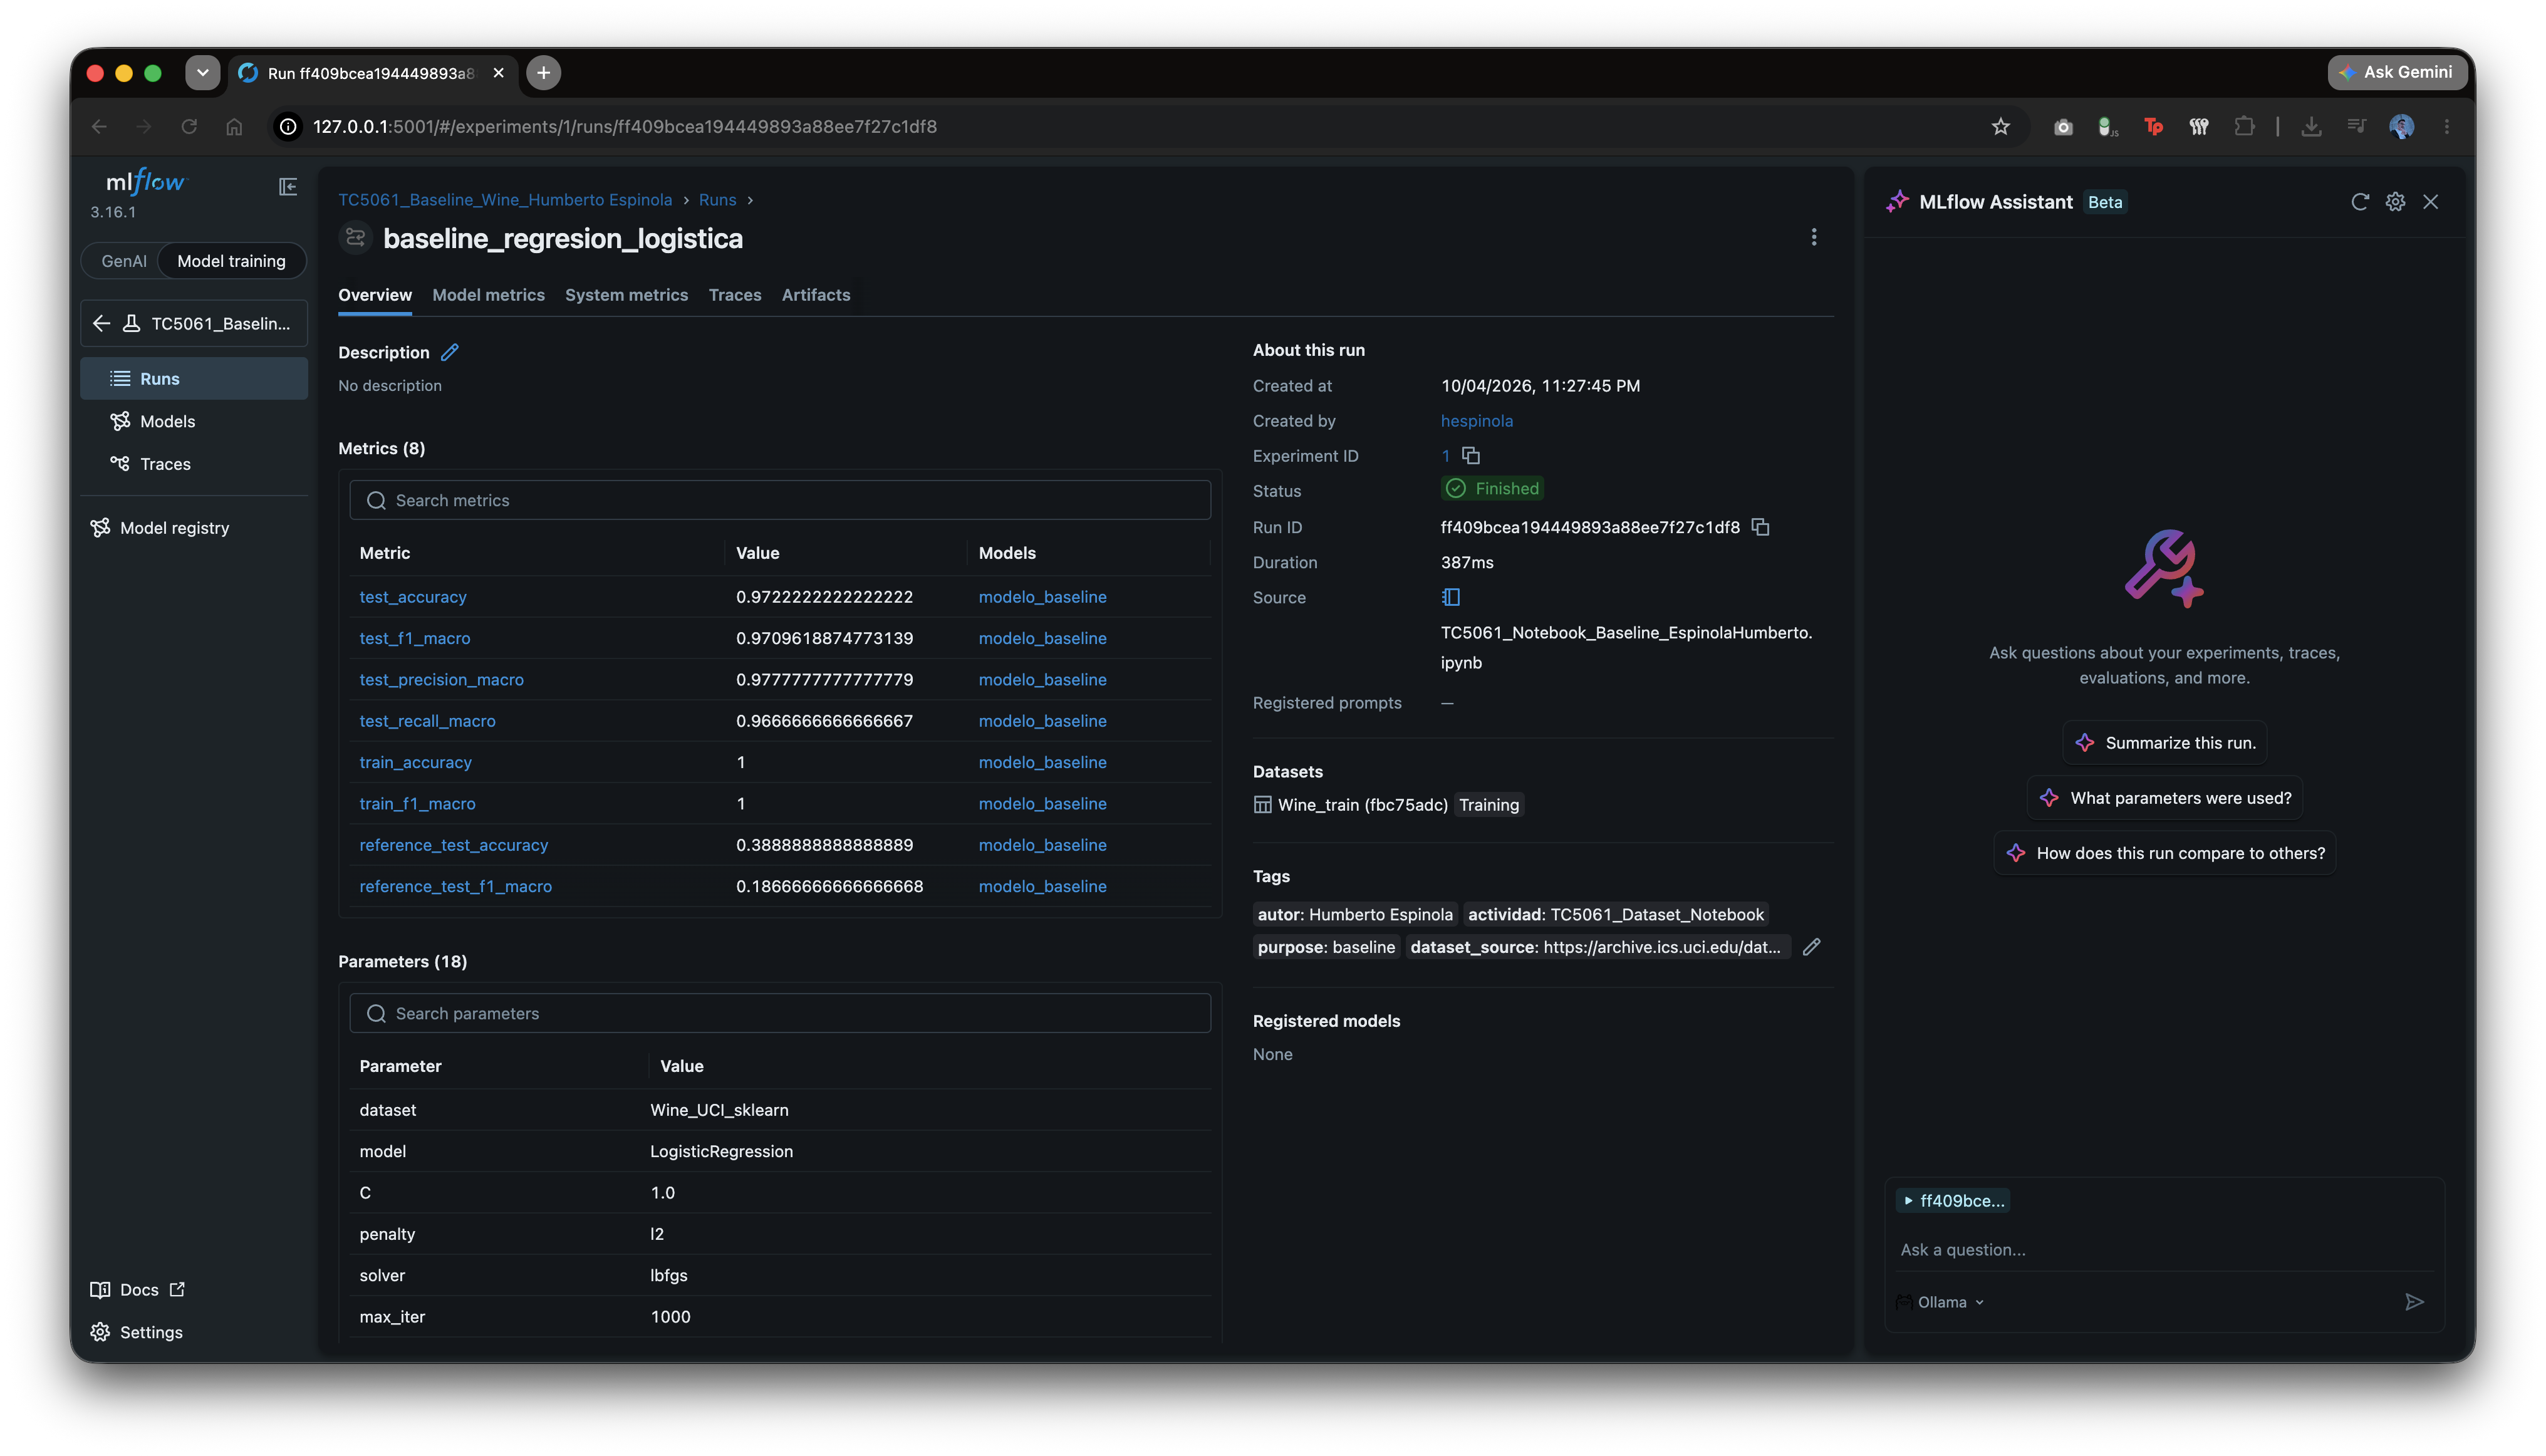

In [20]:
screenshot_path = EVIDENCE_DIR / "mlflow_baseline.png"
if screenshot_path.is_file():
    display(Image(filename=str(screenshot_path)))


### Referencias
- [Wine — UCI](https://archive.ics.uci.edu/dataset/109/wine).
- [load_wine — scikit-learn 1.7](https://scikit-learn.org/1.7/modules/generated/sklearn.datasets.load_wine.html).
- [Regresión logística — scikit-learn 1.7](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [Prevención de fuga de información — scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).
- [MLflow Tracking](https://mlflow.org/docs/latest/ml/tracking/).
- [Registro de modelos scikit-learn — MLflow](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html).

### Uso de inteligencia artificial

OpenAI. (2026). *ChatGPT (GPT-6 Sol)* [Modelo de lenguaje grande], utilizado para generación código inicial y revisión de redacción. https://chat.openai.com/

## 7. Reflexión sobre MLOps

Esta actividad me permitió comprender que establecer un modelo base requiere decisiones consistentes desde la revisión de los datos hasta la evaluación. La ausencia de faltantes o duplicados también debe documentarse, y un valor extremo no debe eliminarse automáticamente. Asimismo, reservar la prueba y ajustar la imputación y estandarización únicamente con entrenamiento ayuda a evitar resultados excesivamente optimistas. Comparar el modelo con una referencia mayoritaria permitió valorar su aporte más allá de observar una métrica alta.

Para mejorar el flujo, versionaría el código, los datos y las dependencias, de manera que cada resultado pudiera relacionarse con una configuración concreta. También incorporaría validaciones automáticas del esquema y pruebas del pipeline dentro de la integración continua. Mantendría MLflow como registro de experimentos y utilizaría validación cruzada dentro del entrenamiento para estudiar nuevas configuraciones, conservando una prueba independiente.

Como Staff Software Engineer en Etsy, principalmente orientado a iOS, relaciono estos aprendizajes con la necesidad de integrar capacidades de Machine Learning de forma verificable y mantenible. Mi interés en Core ML podría llevarme a explorar una futura funcionalidad que ejecute un modelo en el dispositivo. En ese contexto, además de su desempeño predictivo, evaluaría latencia, consumo de memoria, compatibilidad y consistencia del preprocesamiento.

Antes de incorporar una capacidad de este tipo a una aplicación, definiría pruebas de integración, criterios de aceptación y una estrategia de actualización y reversión. El resultado obtenido con Wine no demuestra que un modelo sea adecuado para una funcionalidad real, pero el flujo reproducible ofrece una base para evaluar esa decisión y colaborar con especialistas en datos.
